# Hydrostatics
Edit the inputs, then **Run All**. Displaced volume = mass ÷ water density ([Archimedes](https://www.grc.nasa.gov/WWW/K-12/WindTunnel/Activities/buoy_Archimedes)).

Draft change needs waterplane area; it is a local estimate with fixed area and no trim change. Actual draft, trim and stability need submerged hull geometry.


## Inputs


In [ ]:
MASS_KG = 56.75                      # EDIT THIS: total boat mass in kg.
WATER_DENSITY_KG_M3 = 998.2           # Fresh: 998.2; seawater example: 1025.
MASS_OFFSETS_KG = [-10, -5, 0, 5, 10, 20]   # Changes relative to MASS_KG.
WATERPLANE_AREA_IN2 = None           # Optional: actual area at the waterline, not wetted area.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

KG_PER_LB = 0.45359237
IN_TO_M = 0.0254
G = 9.8066


In [3]:
if not np.isfinite(MASS_KG) or MASS_KG <= 0:
    raise ValueError('MASS_KG must be positive.')
if not np.isfinite(WATER_DENSITY_KG_M3) or WATER_DENSITY_KG_M3 <= 0:
    raise ValueError('Water density must be positive.')
if WATERPLANE_AREA_IN2 is not None and (
        not np.isfinite(WATERPLANE_AREA_IN2) or WATERPLANE_AREA_IN2 <= 0):
    raise ValueError('Waterplane area must be positive, or None.')

offsets = np.unique(np.array([0, *MASS_OFFSETS_KG], dtype=float))
masses = MASS_KG + offsets
if not np.all(np.isfinite(masses)) or np.any(masses <= 0):
    raise ValueError('Every mass, including offsets, must be positive and finite.')

volume_m3 = masses / WATER_DENSITY_KG_M3
base_volume_m3 = MASS_KG / WATER_DENSITY_KG_M3
results = pd.DataFrame({
    'Added mass (kg)': offsets,
    'Total mass (kg)': masses,
    'Total weight (lb)': masses / KG_PER_LB,
    'Displaced water (L)': volume_m3 * 1000,
    'Displaced water (in³)': volume_m3 / IN_TO_M**3,
    'Extra water (L)': (volume_m3 - base_volume_m3) * 1000,
    'Extra displaced volume (in³)': (volume_m3 - base_volume_m3) / IN_TO_M**3,
    'Buoyancy (N)': masses * G,
})
if WATERPLANE_AREA_IN2 is not None:
    area_m2 = WATERPLANE_AREA_IN2 * IN_TO_M**2
    results['Sinkage change (in)'] = (volume_m3 - base_volume_m3) / area_m2 / IN_TO_M

print(f'Current: {MASS_KG:.2f} kg / {MASS_KG / KG_PER_LB:.2f} lb → '
      f'{base_volume_m3 * 1000:.2f} L / {base_volume_m3 / IN_TO_M**3:.0f} in³ displaced')
print(f'Each extra kg needs {1000 / WATER_DENSITY_KG_M3:.3f} L more displaced water.')
display(results.round(2))


Current: 56.75 kg / 125.11 lb → 55.37 L / 3379 in³ displaced
Each extra kg needs 0.976 L more displaced water.


,Added mass (kg),Total mass (kg),Total weight (lb),Displaced water (L),Displaced water (in³),Extra water (L),Extra displaced volume (in³),Buoyancy (N)
0,-10.0,46.75,103.07,45.61,2783.28,-9.76,-595.35,458.46
1,-5.0,51.75,114.09,50.49,3080.95,-4.88,-297.68,507.49
2,0.0,56.75,125.11,55.37,3378.63,0.00,0.00,556.52
3,5.0,61.75,136.14,60.24,3676.31,4.88,297.68,605.56
4,10.0,66.75,147.16,65.12,3973.99,9.76,595.35,654.59
5,20.0,76.75,169.20,74.88,4569.34,19.51,1190.71,752.66


## Graphs


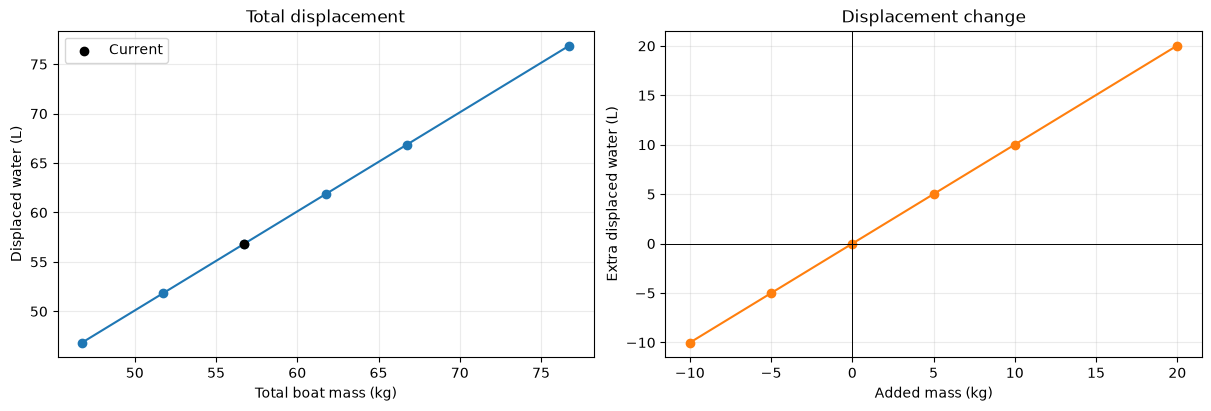

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

axes[0].plot(masses, volume_m3 * 1000, marker='o', color='tab:blue')
axes[0].scatter([MASS_KG], [base_volume_m3 * 1000], color='black', zorder=3, label='Current')
axes[0].set(xlabel='Total boat mass (kg)', ylabel='Displaced water (L)', title='Total displacement')
axes[0].legend()

if WATERPLANE_AREA_IN2 is not None:
    axes[1].plot(offsets, results['Sinkage change (in)'], marker='o', color='tab:orange')
    axes[1].set(ylabel='Sinkage change (in; positive = down)', title='Draft change — fixed waterplane area')
else:
    axes[1].plot(offsets, (volume_m3 - base_volume_m3) * 1000, marker='o', color='tab:orange')
    axes[1].set(ylabel='Extra displaced water (L)', title='Displacement change')
axes[1].set_xlabel('Added mass (kg)')
axes[1].axhline(0, color='black', linewidth=0.7)
axes[1].axvline(0, color='black', linewidth=0.7)
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()
